In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 读取TSV文件，并命名为Sig_Eqs,查看数据类型
Sig_Eqs=pd.read_csv("D:\ESE5023\earthquakes-2026-10-14_20-34-14_+0800.tsv",sep="\t")
Sig_Eqs.info()

<class 'pandas.DataFrame'>
RangeIndex: 6698 entries, 0 to 6697
Data columns (total 49 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Search Parameters                   1 non-null      str    
 1   Id                                  6697 non-null   float64
 2   Year                                6697 non-null   float64
 3   Mo                                  6293 non-null   float64
 4   Dy                                  6122 non-null   float64
 5   Hr                                  4580 non-null   float64
 6   Mn                                  4357 non-null   float64
 7   Sec                                 3864 non-null   float64
 8   Tsu                                 2124 non-null   float64
 9   Vol                                 82 non-null     float64
 10  Country                             6697 non-null   str    
 11  Area                                335 non-null    st

In [2]:
#1.1

deaths=Sig_Eqs.groupby("Country")["Total Deaths"].sum()
deaths=deaths.sort_values(ascending=False)
print(deaths.head(20))

Country
CHINA           2106526.0
TURKEY          1008867.0
IRAN             761656.0
SYRIA            488326.0
ITALY            417297.0
HAITI            323782.0
JAPAN            319510.0
AZERBAIJAN       319251.0
INDONESIA        283485.0
ARMENIA          175000.0
PAKISTAN         143714.0
ECUADOR          134445.0
TURKMENISTAN     110412.0
PERU              97009.0
GREECE            83658.0
PORTUGAL          82572.0
IRAQ              70200.0
CHILE             70175.0
INDIA             63413.0
ISRAEL            58368.0
Name: Total Deaths, dtype: float64


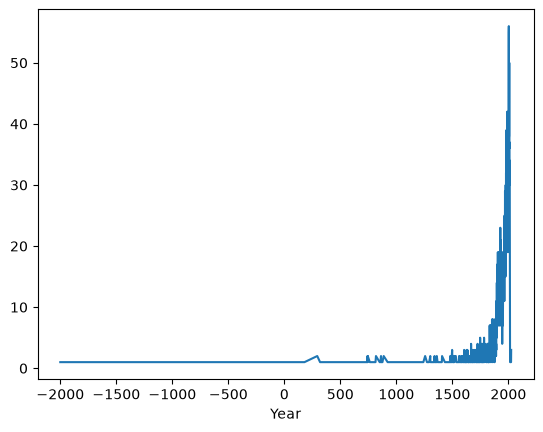

In [3]:
#1.2

eq=Sig_Eqs.loc[(Sig_Eqs['Ms']>3)].groupby("Year").size()
eq = eq.sort_index()
eq.plot()
plt.show()

In [4]:
#1.3

def CountEq_LargestEq(country):
    # 选出这个国家所有地震
    country_eq = Sig_Eqs[Sig_Eqs['Country'] == country]
    
    # 统计这个国家地震总数量
    eq_num = len(country_eq)
    
    # 筛选有Ms震级的数据
    country_eq_ms = country_eq.dropna(subset=['Ms'])
    
    # 如果这个国家所有地震都没有Ms震级
    if len(country_eq_ms) == 0:
        return eq_num, 'unknown magnitude', 'unknown date', 'unknown location'
    
    # 找到Ms最大的那一行
    max_index = country_eq_ms['Ms'].idxmax()
    max_eq = country_eq_ms.loc[max_index]
    
    # 取出日期和地点
    max_ms = max_eq['Ms']
    year = max_eq['Year']
    month = max_eq['Mo']
    day = max_eq['Dy']
    location = max_eq['Location Name']
    date_str = str(year) + '-' + str(month) + '-' + str(day)
    
    return eq_num, max_ms, date_str, location

result = []

# 获取所有不同国家
all_countries = Sig_Eqs['Country'].unique()

# 循环每个国家，调用函数
for one_country in all_countries:
    count, mag, date, loc = CountEq_LargestEq(one_country)

    temp = {
        'Country': one_country,
        'Total_Earthquake': count,
        'Largest_Ms': mag,
        'Largest_Date': date,
        'Largest_Location': loc
    }
    result.append(temp)

result = pd.DataFrame(result)
result = result.sort_values('Total_Earthquake', ascending=False)
result

,Country,Total_Earthquake,Largest_Ms,Largest_Date,Largest_Location
15,CHINA,626,8.6,1920.0-12.0-16.0,"CHINA: GANSU PROVINCE, SHANXI PROVINCE"
34,JAPAN,429,8.6,869.0-7.0-13.0,JAPAN: SANRIKU
74,INDONESIA,427,8.8,2004.0-12.0-26.0,INDONESIA: SUMATRA: ACEH: OFF WEST COAST
8,IRAN,385,7.9,856.0-12.0-22.0,"IRAN: DAMGHAN, QUMIS"
10,TURKEY,359,7.8,1939.0-12.0-26.0,TURKEY: ERZINCAN
...,...,...,...,...,...
155,BURUNDI,1,unknown magnitude,unknown date,unknown location
161,ZAMBIA,1,unknown magnitude,unknown date,unknown location
160,MADAGASCAR,1,unknown magnitude,unknown date,unknown location
162,COMOROS,1,unknown magnitude,unknown date,unknown location


C:\Users\islovenia\AppData\Local\Temp\ipykernel_114168\3898196232.py:2: DtypeWarning: Columns (0: CALL_SIGN, 1: AA3, 2: AG1, 3: AJ1, 4: AW1, 5: AZ1, 6: CALL_SIGN.1, 7: GA5, 8: GE1, 9: HL1, 10: IA2, 11: KA2, 12: ME1, 13: MW3, 14: OA1, 15: OD1, 16: OD2, 17: SA1, 18: UA1, 19: UG1) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("Baoan_Weather_1998_2022.csv")


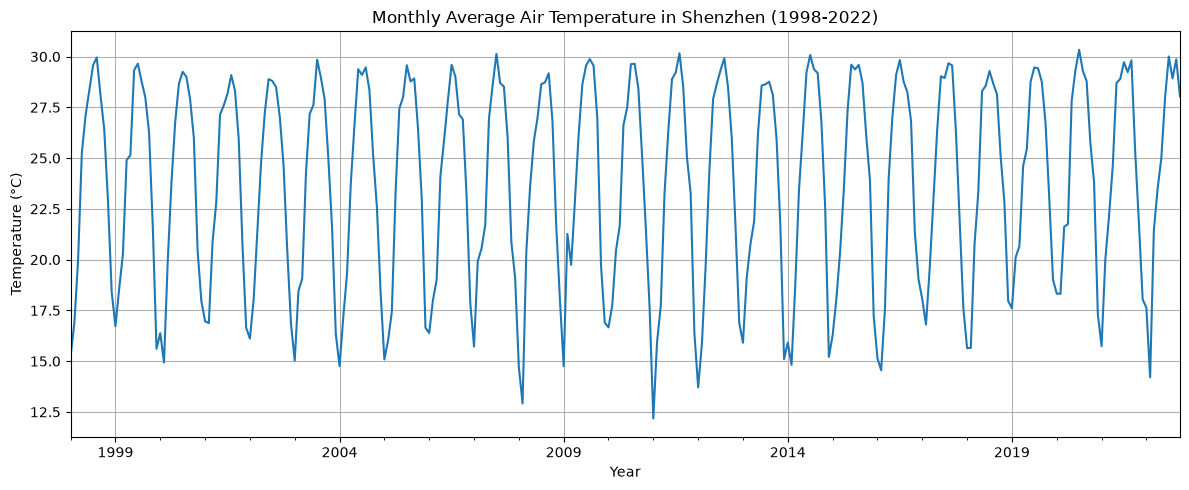

In [5]:
#  读取天气数据
data = pd.read_csv("Baoan_Weather_1998_2022.csv")

#  将日期转换为日期格式
data["DATE"] = pd.to_datetime(data["DATE"])

#  提取温度值和质量代码
data["TMP"] = data["TMP"].astype(str)
data["Quality"] = data["TMP"].str.split(",").str[1]
data["TMP"] = data["TMP"].str.split(",").str[0]

#  将温度转换为数字
data["TMP"] = pd.to_numeric(data["TMP"])

#  删除温度缺失值
data = data[(data["TMP"] != 9999) &
            (data["TMP"] != -9999)]

#  将温度转换为摄氏度
data["TMP"] = data["TMP"] / 10

#  保留指定质量代码的数据
data = data[data["Quality"].isin(["0", "1", "4", "5", "9"])]

#  删除其他缺失值
data = data.dropna(subset=["DATE", "TMP"])

#  按月份计算平均气温
data["Month"] = data["DATE"].dt.to_period("M")
monthly_temp = data.groupby("Month")["TMP"].mean()

#  绘制月平均气温变化图
monthly_temp.plot(figsize=(12, 5))

plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.title("Monthly Average Air Temperature in Shenzhen (1998-2022)")
plt.grid()
plt.tight_layout()
plt.show()

In [6]:
df = pd.read_csv("D:\ESE5023\ibtracs.ALL.list.v04r00.csv",
                 usecols=range(17),
                 skiprows=[1, 2], 
                 parse_dates=['ISO_TIME'],
                 na_values=['NOT_NAMED', 'NAME'])
df.head()

C:\Users\islovenia\AppData\Local\Temp\ipykernel_114168\2422779827.py:1: DtypeWarning: Columns (0: NAME) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("D:\ESE5023\ibtracs.ALL.list.v04r00.csv",


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,,,,main,0,0,__________P___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,,,,main,0,0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,,,,main,0,0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,,,,main,0,0,__________O___
4,1842298N11080,1842,1,NI,AS,NaN,1842-10-25 18:00:00,NR,10.7884,77.9194,,,,main,0,0,__________P___


In [7]:
#3.1
#按风暴编号分组，找出每个风暴的最大风速,按最大风速从高到低排序，列出前10个
strom=df.groupby(["SID", "NAME"])["WMO_WIND"].max()
strom=strom.sort_values(ascending=False)
print(strom.head(10))

SID            NAME   
1950224N17305  ABLE       95
1950234N11334  CHARLIE    95
1950244N20277  EASY       95
1950251N16319  FOX        95
1950270N25309  GEORGE     95
1951224N12316  CHARLIE    95
1951244N13328  EASY       95
1951246N13340  FOX        95
1952244N15306  BAKER      95
1952268N20291  CHARLIE    95
Name: WMO_WIND, dtype: str


In [8]:
#3.2
print(strom.head(20))

SID            NAME    
1950224N17305  ABLE        95
1950234N11334  CHARLIE     95
1950244N20277  EASY        95
1950251N16319  FOX         95
1950270N25309  GEORGE      95
1951224N12316  CHARLIE     95
1951244N13328  EASY        95
1951246N13340  FOX         95
1952244N15306  BAKER       95
1952268N20291  CHARLIE     95
1952295N11282  FOX         95
1953240N14340  CAROL       95
1953258N19296  EDNA        95
1953267N15282  FLORENCE    95
1954176N22266  ALICE       95
1954238N24285  CAROL       95
1954248N20295  EDNA        95
1954278N12302  HAZEL       95
1955215N15320  CONNIE      95
1955253N14319  IONE        95
Name: WMO_WIND, dtype: str


In [9]:
#3.3
basin=df["BASIN"].value_counts()
print(basin)

BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55401
SA       119
Name: count, dtype: int64


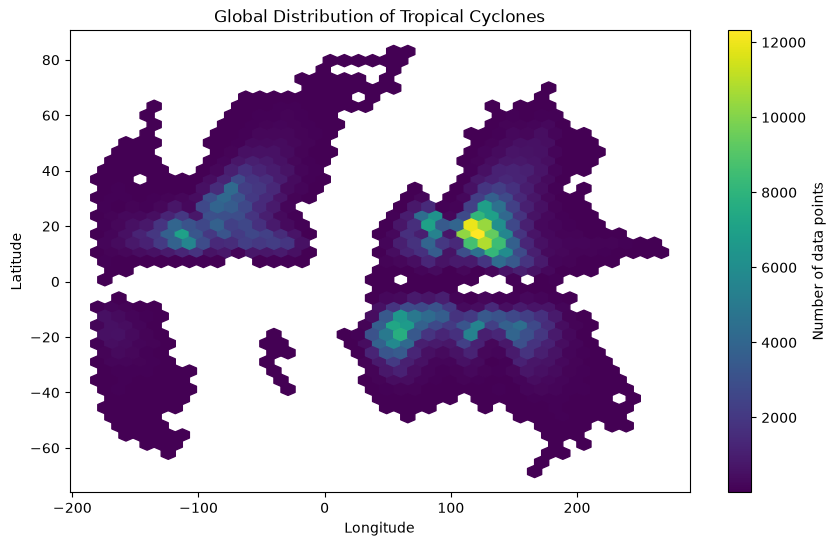

In [16]:
#3.4
#  绘制六边形分箱图
location_data = df.dropna(subset=["LAT", "LON"])
plt.figure(figsize=(10, 6))

plt.hexbin(location_data["LON"], location_data["LAT"],
           gridsize=40, mincnt=1, cmap="viridis")

plt.colorbar(label="Number of data points")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Global Distribution of Tropical Cyclones")
plt.show()

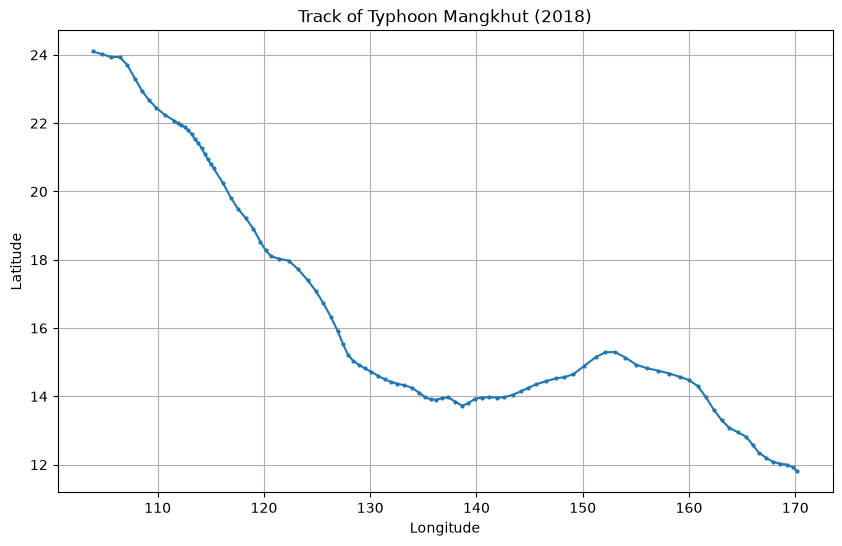

In [12]:
#3.5
# 筛选2018年的台风山竹
mangkhut = df[
    (df["NAME"].str.strip() == "MANGKHUT") &
    (df["ISO_TIME"].dt.year == 2018)
].copy()

# 按观测时间排序
mangkhut = mangkhut.sort_values("ISO_TIME")

# 绘制台风移动路径
plt.figure(figsize=(10, 6))
plt.plot(mangkhut["LON"], mangkhut["LAT"], marker="o",
         markersize=2)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Track of Typhoon Mangkhut (2018)")
plt.grid()
plt.show()

In [13]:
#3.6
# 筛选1970年及之后、来自WP和EP海盆的数据
df_filtered = df[
    (df["ISO_TIME"].dt.year >= 1970) &
    (df["BASIN"].isin(["WP", "EP"]))
].copy()

# 查看筛选后的数据
print(df_filtered.head())

                  SID  SEASON  NUMBER BASIN SUBBASIN   NAME  \
350393  1970050N07151    1970      22    WP       MM  NANCY   
350394  1970050N07151    1970      22    WP       MM  NANCY   
350395  1970050N07151    1970      22    WP       MM  NANCY   
350396  1970050N07151    1970      22    WP       MM  NANCY   
350397  1970050N07151    1970      22    WP       MM  NANCY   

                  ISO_TIME NATURE      LAT      LON WMO_WIND WMO_PRES  \
350393 1970-02-19 00:00:00     TS  7.00000  151.400              1006   
350394 1970-02-19 03:00:00     TS  7.24752  151.205                     
350395 1970-02-19 06:00:00     TS  7.50000  151.000              1002   
350396 1970-02-19 09:00:00     TS  7.75747  150.772                     
350397 1970-02-19 12:00:00     TS  8.00000  150.500               998   

       WMO_AGENCY TRACK_TYPE  DIST2LAND LANDFALL           IFLAG  
350393      tokyo       main       1088     1088  _OO___________  
350394                  main       1109     1109

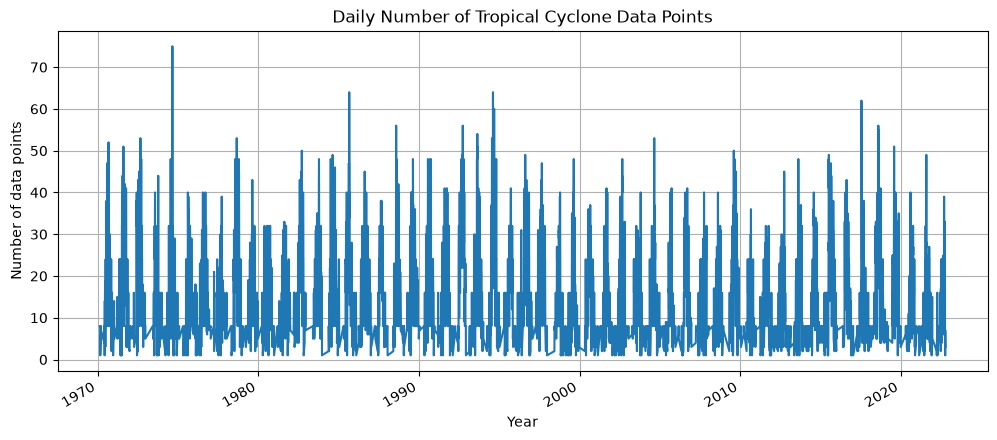

In [21]:
#3.7
# 统计每天的数据点数量
daily_count = df_filtered.groupby(df_filtered["ISO_TIME"].dt.date).size()

# 将索引转换为日期格式
daily_count.index = pd.to_datetime(daily_count.index)

# 绘制每日数据点数量
daily_count.plot(figsize=(12, 5))

plt.xlabel("Year")
plt.ylabel("Number of data points")
plt.title("Daily Number of Tropical Cyclone Data Points")
plt.grid()
plt.show()

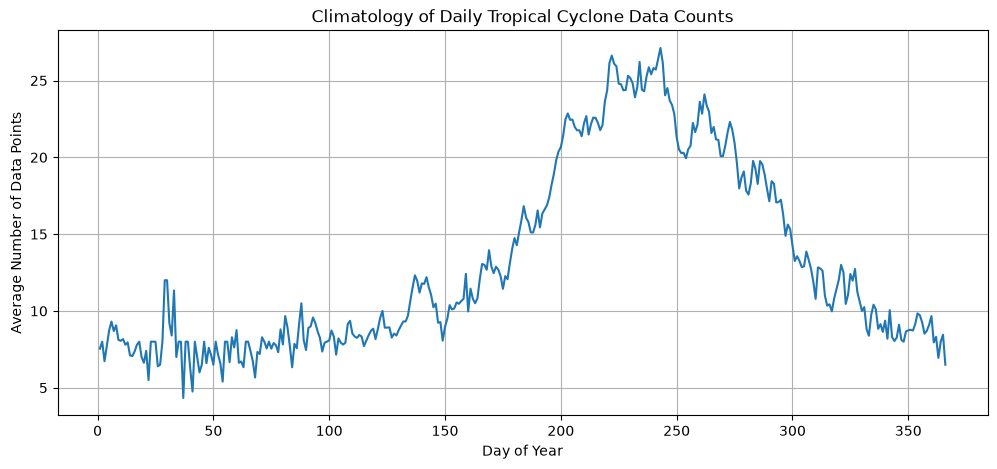

In [25]:
#3.8
# 创建数据表
daily_data = daily_count.to_frame(name="Count")

daily_data["DayOfYear"] = daily_data.index.dayofyear
# 计算每个日期序号的数据点数量平均值
climatology = daily_data.groupby("DayOfYear")["Count"].mean()

# 绘制气候平均值
climatology.plot(figsize=(12, 5))

plt.xlabel("Day of Year")
plt.ylabel("Average Number of Data Points")
plt.title("Climatology of Daily Tropical Cyclone Data Counts")
plt.grid()
plt.show()

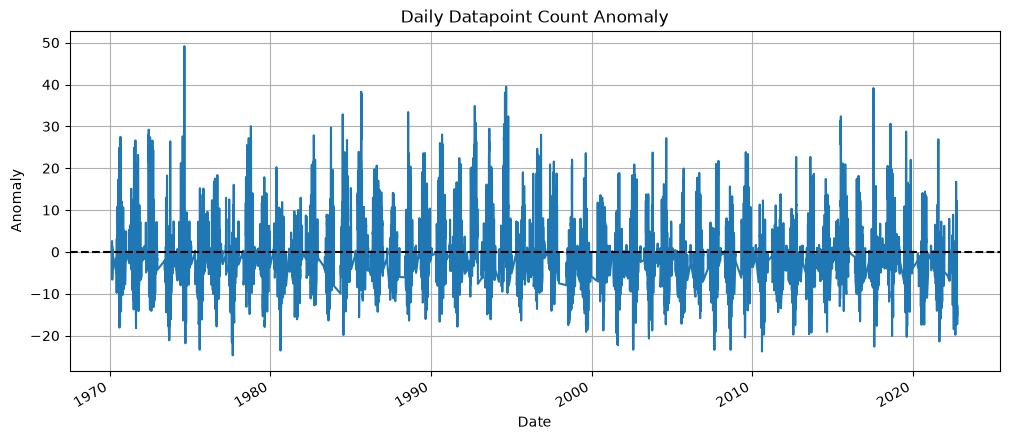

In [26]:
#3.9
# 计算每一天对应的气候平均值
daily_data["Climatology"] = daily_data["DayOfYear"].map(climatology)

# 计算每日异常值
daily_data["Anomaly"] = daily_data["Count"] - daily_data["Climatology"]

# 绘制每日异常值
daily_data["Anomaly"].plot(figsize=(12, 5))

plt.axhline(y=0, color="black", linestyle="--")
plt.xlabel("Date")
plt.ylabel("Anomaly")
plt.title("Daily Datapoint Count Anomaly")
plt.grid()
plt.show()

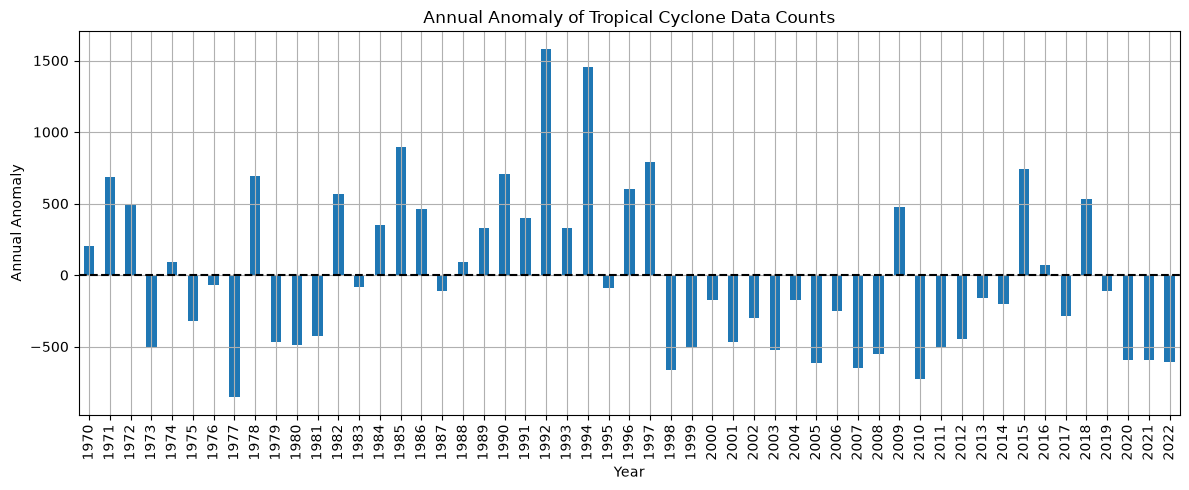

In [48]:
#3.10
# 提取每条数据对应的年份
daily_data["Year"] = daily_data.index.year

# 按年份计算异常值总和
annual_anomaly = daily_data.groupby("Year")["Anomaly"].sum()

# 绘制年度异常值
annual_anomaly.plot(kind="bar", figsize=(12, 5))

plt.axhline(y=0, color="black", linestyle="--")
plt.xlabel("Year")
plt.ylabel("Annual Anomaly")
plt.title("Annual Anomaly of Tropical Cyclone Data Counts")
plt.grid()
plt.tight_layout()
plt.show()

<class 'pandas.DataFrame'>
RangeIndex: 236 entries, 0 to 235
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   STATION          236 non-null    str    
 1   NAME             236 non-null    str    
 2   LATITUDE         236 non-null    float64
 3   LONGITUDE        236 non-null    float64
 4   ELEVATION        236 non-null    float64
 5   DATE             236 non-null    str    
 6   TAVG             236 non-null    int64  
 7   TAVG_ATTRIBUTES  236 non-null    str    
 8   TMAX             105 non-null    float64
 9   TMAX_ATTRIBUTES  105 non-null    str    
 10  TMIN             219 non-null    float64
 11  TMIN_ATTRIBUTES  219 non-null    str    
dtypes: float64(5), int64(1), str(6)
memory usage: 32.0 KB
       STATION           NAME  LATITUDE  LONGITUDE  ELEVATION        DATE  \
0  CHM00059287  GUANGZHOU, CH    23.217    113.483       71.0  2025-01-01   
1  CHM00059287  GUANGZHOU, CH    23.217    113.48

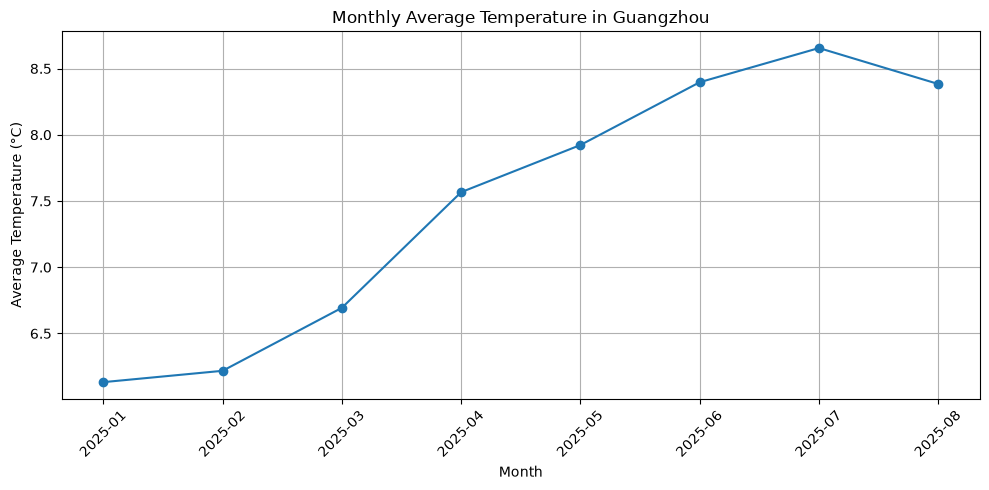

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

#  读取CSV文件
gz = pd.read_csv(r"D:\ESE5023\4420511.csv")
gz.info()

# 删除日期或平均气温缺失的数据
gz = gz.dropna(subset=["DATE", "TAVG"])

# 将气温从十分之一摄氏度转换为摄氏度
gz["TAVG"] = (gz["TAVG"] / 10 )

# 查看清洗后的数据
print(gz.head())
print("数据总数：", len(gz))
print("缺失值数量：")
print(gz[["DATE", "TAVG"]].isnull().sum())



# 绘制每月平均气温时间序列
# 将日期列转换为日期格式
gz["DATE"] = pd.to_datetime(gz["DATE"], errors="coerce")
# 提取年份和月份
gz["YearMonth"] = gz["DATE"].dt.to_period("M")

# 计算每月平均气温
monthly_avg = gz.groupby("YearMonth")["TAVG"].mean()

# 绘制折线图
plt.figure(figsize=(10, 5))
plt.plot(monthly_avg.index.astype(str), monthly_avg.values, marker="o")

plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.title("Monthly Average Temperature in Guangzhou")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [47]:
#  进行统计分析
print("平均气温：", round(gz["TAVG"].mean(), 2), "°C")
print("气温中位数：", round(gz["TAVG"].median(), 2), "°C")
print("气温标准差：", round(gz["TAVG"].std(), 2), "°C")
print("最高平均气温：", round(gz["TAVG"].max(), 2), "°C")
print("最低平均气温：", round(gz["TAVG"].min(), 2), "°C")
print("有效数据总数：", len(gz))

平均气温： 7.48 °C
气温中位数： 7.8 °C
气温标准差： 1.1 °C
最高平均气温： 9.2 °C
最低平均气温： 5.0 °C
有效数据总数： 236
